# Diffusion inside a sphere: manual test
Loads `DiffusionInSphere`, plots its weights, compares it with the Mantid formula and the Bicout integral, fits synthetic and tutorial data, tests the fit loop and fits the EISF against Q.

$$A_0 = \left(\frac{3 j_1(QR)}{QR}\right)^2,\quad A_{nl} = (2l+1)\frac{6x_{nl}^2}{x_{nl}^2 - l(l+1)}\left(\frac{QR\,j_{l+1}(QR) - l\,j_l(QR)}{(QR)^2 - x_{nl}^2}\right)^2,\quad \Gamma_{nl} = \frac{\hbar x_{nl}^2 D}{R^2}$$

In [1]:
import numpy as np
import plopp as pp
import scipp as sc
from scipp.constants import hbar

import easydynamics as edyn

## Load
The model with the true parameters, at six Q values.

In [2]:
Q = sc.linspace('Q', 0.4, 2.0, 6, unit='1/angstrom')
energy = sc.linspace('energy', -2.0, 2.0, 401, unit='meV')
Q_fine = sc.linspace('Q', 0.02, 3.0, 300, unit='1/angstrom')
hbar_meV_ps = hbar.to(unit='meV*ps').value


def versus_Q(values, unit='dimensionless'):
    """A model quantity on Q_fine as a DataArray, for plopp."""
    return sc.DataArray(sc.array(dims=['Q'], values=values, unit=unit), coords={'Q': Q_fine})

In [3]:
import time

true_parameters = {'scale': 1.0, 'radius': 3.0, 'diffusion_coefficient': 0.1}  # D in Å²/ps

start = time.perf_counter()
model = edyn.DiffusionInSphere(Q=Q.values, **true_parameters)
{
    'build, 6 Q (s)': round(time.perf_counter() - start, 1),
    'terms': model.number_of_lorentzians,
    'D as stored': str(model.diffusion_coefficient),
}

/home/mark/Projects/dynamics-lib/src/easydynamics/sample_model/diffusion_model/diffusion_in_sphere.py:273: UserWarning: Truncating the sum at number_of_lorentzians=10 omits more than 0.001 of the spectral weight at some Q values. At most 98 terms are available (the roots below 26.84, the same limit as Mantid); with all of them this happens from QR of about 10.
  self.create_component_collections()


{'build, 6 Q (s)': 1.2,
 'terms': 10,
 'D as stored': "<Parameter 'diffusion_coefficient': 1.000e-09 m^2/s, bounds=[1.0000000000000001e-20:inf]>"}

## Plot
Model quantities against Q, each with its limiting case.

EISF for several radii, and the weights of the first terms.

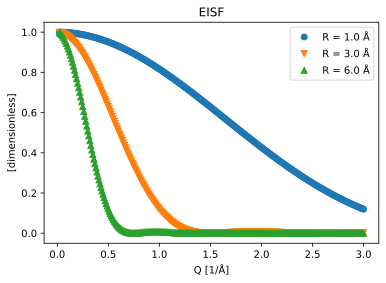

In [4]:
pp.plot(
    {
        f'R = {r} Å': versus_Q(edyn.DiffusionInSphere(radius=r).calculate_EISF(Q_fine.values))
        for r in (1.0, 3.0, 6.0)
    },
    title='EISF',
)

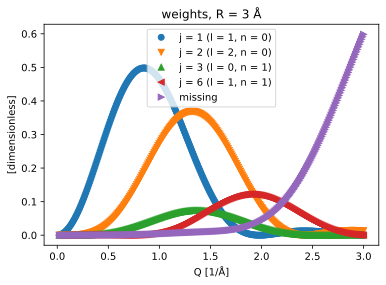

In [5]:
curves = {}
for j in (1, 2, 3, 6):
    x, angular_order, n = model.roots[j - 1]
    curves[f'j = {j} (l = {angular_order}, n = {n})'] = versus_Q(
        model.calculate_QISF_order(Q_fine.values, j)
    )
curves['missing'] = versus_Q(model.calculate_missing_weight(Q_fine.values))
pp.plot(curves, title='weights, R = 3 Å')

## Compare with the references
QENSmodels has no sphere model. The spectrum is compared with Mantid's `InelasticDiffSphere` formula, written out here with scipy, and the weights with Bicout's overlap integral (Eq. 2.12).

In [6]:
from scipy.integrate import quad
from scipy.special import spherical_jn as scipy_jn

# Mantid InelasticDiffSphere's formula, re-implemented independently over the model's
# number_of_lorentzians lowest roots (Mantid sums all 98): weights
# (2l+1) 6x^2/(x^2 - l(l+1)) J^2 with the direct J, which is accurate unless QR is within about
# 1e-3 of a root (the 0/0 point; Mantid itself interpolates within 0.1 of each root instead).
x_nl = np.array([root[0] for root in model.roots])
l_nl = np.array([root[1] for root in model.roots])
R = true_parameters['radius']
spectrum_differences = []
for i, q in enumerate(Q.values):
    a = q * R
    assert np.min(np.abs(a - x_nl)) > 1e-3, (q, a)
    J = (a * scipy_jn(l_nl + 1, a) - l_nl * scipy_jn(l_nl, a)) / (a**2 - x_nl**2)
    weights = (2 * l_nl + 1) * 6 * x_nl**2 / (x_nl**2 - l_nl * (l_nl + 1)) * J**2
    widths = (
        hbar
        * sc.scalar(true_parameters['diffusion_coefficient'], unit='angstrom**2/ps')
        / sc.scalar(R, unit='angstrom') ** 2
    ).to(unit='meV').value * x_nl**2
    E = energy.values[energy.values != 0]
    mantid = np.sum(
        weights[:, None] * widths[:, None] / np.pi / (widths[:, None] ** 2 + E**2), axis=0
    )
    ours = sum(component.evaluate(E) for component in model.get_component_collections()[i][1:])
    spectrum_differences.append(float(np.max(np.abs(ours - mantid)) / np.max(mantid)))

# Bicout, PRE 62, 261 (2000), Eq. 2.12, single sphere of radius 1
bicout_differences = []
for j, (x, order, _) in enumerate(model.roots[:5], start=1):
    Z = quad(
        lambda r, x=x, order=order: r * r * scipy_jn(order, x * r) ** 2,
        0,
        1,
        epsabs=1e-15,
        epsrel=1e-12,
    )[0]
    for QR in (0.3, 1.7, 4.2):
        overlap = quad(
            lambda r, x=x, order=order, QR=QR: (
                3**0.5 * r * r * scipy_jn(order, QR * r) * scipy_jn(order, x * r)
            ),
            0,
            1,
            epsabs=1e-14,
            epsrel=1e-12,
            limit=200,
        )[0]
        unit_sphere = edyn.DiffusionInSphere(radius=1.0)
        expected = (2 * order + 1) * overlap**2 / Z
        bicout_differences.append(
            abs(unit_sphere.calculate_QISF_order(np.array([QR]), j)[0] - expected) / expected
        )
reference_difference = max(spectrum_differences)
assert reference_difference < 1e-9, spectrum_differences
assert max(bicout_differences) < 1e-10, bicout_differences
{
    'max relative difference to Mantid formula': reference_difference,
    'max relative difference to Bicout integral': max(bicout_differences),
}

{'max relative difference to Mantid formula': 4.935486566250747e-15,
 'max relative difference to Bicout integral': np.float64(6.194820869695222e-15)}

## Synthetic data
The model with the true parameters is evaluated on a (Q, energy) grid through an `Analysis`,
plus Gaussian noise with a fixed $\sigma$. A first `Experiment` holds placeholder data with the
right coordinates, so that `Analysis.calculate` knows the grid.

/home/mark/Projects/dynamics-lib/src/easydynamics/sample_model/diffusion_model/delta_lorentzian_diffusion_model_base.py:509: UserWarning: Truncating the sum at number_of_lorentzians=10 omits more than 0.001 of the spectral weight at some Q values. At most 98 terms are available (the roots below 26.84, the same limit as Mantid); with all of them this happens from QR of about 10.
  self.create_component_collections()


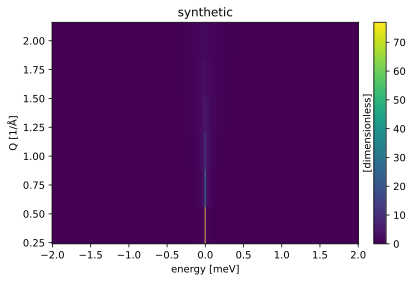

In [7]:
sigma = 0.003
shape = (Q.shape[0], energy.shape[0])


def as_data(values, variances):
    return sc.DataArray(
        sc.array(dims=['Q', 'energy'], values=values, variances=variances),
        coords={'Q': Q, 'energy': energy},
    )


experiment = edyn.Experiment('synthetic', data=as_data(np.ones(shape), np.ones(shape)))
true_analysis = edyn.Analysis(
    experiment=experiment, sample_model=edyn.SampleModel(diffusion_models=model)
)
clean = np.array(true_analysis.calculate())
rng = np.random.default_rng(seed=1)
experiment.data = as_data(clean + rng.normal(0.0, sigma, shape), np.full(shape, sigma**2))
experiment.plot_data(slicer=False)

$S(Q, E)$ without noise, one curve per Q.

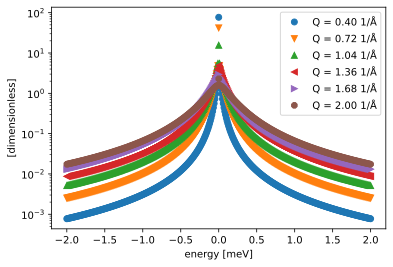

In [8]:
sqw = sc.DataArray(
    sc.array(dims=['Q', 'energy'], values=clean, unit=model.y_unit),
    coords={'Q': Q, 'energy': energy},
)
pp.plot({f'Q = {q:.2f} 1/Å': sqw['Q', i] for i, q in enumerate(Q.values)}, norm='log')

## Fit to the synthetic data
A new model with wrong start values, fitted simultaneously over all Q. The synthetic data has no
energy offset, so it is fixed: with a delta function on the energy grid, a free offset can stop
the minimizer early while it still reports success (see the last cell).

In [9]:
fitted_parameters = {
    'scale': 1.0,
    'radius': 3.0,
    'diffusion_coefficient': 1e-9,
}  # D as stored: 0.1 Å²/ps = 1e-9 m²/s
fit_model = edyn.DiffusionInSphere(scale=0.7, radius=2.5, diffusion_coefficient=0.07)
fit_analysis = edyn.Analysis(
    experiment=experiment, sample_model=edyn.SampleModel(diffusion_models=fit_model)
)
fit_analysis.fix_energy_offset()
results = fit_analysis.fit(fit_method='simultaneous')
fit_model

/home/mark/Projects/dynamics-lib/src/easydynamics/sample_model/diffusion_model/delta_lorentzian_diffusion_model_base.py:509: UserWarning: Truncating the sum at number_of_lorentzians=10 omits more than 0.001 of the spectral weight at some Q values. At most 98 terms are available (the roots below 26.84, the same limit as Mantid); with all of them this happens from QR of about 10.
  self.create_component_collections()
CollectionBase is deprecated and will be removed in a future version. Please migrate to ModelBase or EasyList.


DiffusionInSphere(name='DiffusionInSphere', display_name='DiffusionInSphere',
x_unit=meV, y_unit=dimensionless,
    radius=<Parameter 'radius': 3.0001 ± 0.0001 Å, bounds=[1e-10:inf]>,
    diffusion_coefficient=<Parameter 'diffusion_coefficient': 1.000e-09 ± 1.863e-13 m^2/s, bounds=[1.0000000000000001e-20:inf]>,
    number_of_lorentzians=10,
    scale=<Parameter 'scale': 1.0001 ± 0.0000 meV, bounds=[0.0:inf]>)

Data and fitted model at the lowest and highest Q. In Jupyter with `%matplotlib widget`, `fit_analysis.plot_data_and_model()` shows all Q with a slider.

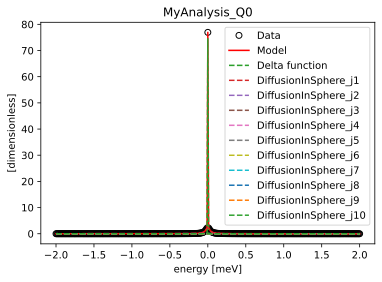

In [10]:
fit_analysis.plot_data_and_model(Q_index=0)

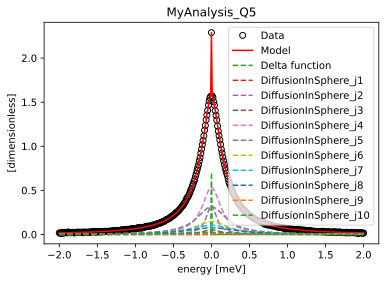

In [11]:
fit_analysis.plot_data_and_model(Q_index=len(Q) - 1)

### Check
The fitted values must lie within 5 standard errors of the true values, and the reduced
$\chi^2$ must be close to 1. This cell raises if they do not.

In [12]:
model_values = np.array(fit_analysis.calculate())
residuals = (experiment.data.values - model_values) / sigma
reduced_chi2 = float(np.sum(residuals**2) / model_values.size)
deviations = {
    name: (getattr(fit_model, name).value - true_value) / getattr(fit_model, name).error
    for name, true_value in fitted_parameters.items()
}
assert all(abs(d) < 5 for d in deviations.values()), 'a fitted value is more than 5 sigma off'
assert 0.9 < reduced_chi2 < 1.1, 'reduced chi2 is far from 1'
{'reduced chi2': reduced_chi2} | {
    f'{name}: (fit - true) / error': d for name, d in deviations.items()
}

{'reduced chi2': 1.0077710349131443,
 'scale: (fit - true) / error': np.float64(1.3566960528002816),
 'radius: (fit - true) / error': np.float64(0.3969229527804407),
 'diffusion_coefficient: (fit - true) / error': np.float64(-0.09015742962917775)}

The tutorial fit, the fit loop and the EISF fit are in `diffusion_in_sphere_manual_part_2.ipynb`.

## Bugs found
Found while building and testing this model, each reproduced in this session (2026-10-23) on
easyscience 2.5.1, scipp 26.9.0 and NumPy 2.5.4 unless stated otherwise; to be reported.

**EasyScience Core**
1. `(1/Å²) × Å²` gets the unit `0.999999999999999889` instead of `dimensionless`;
   `convert_unit('dimensionless')` does not fix it, and adding a plain number then raises
   `UnitError: Numbers can only be added to dimensionless values`. Hits $Q^2\langle u^2\rangle$.
2. `Parameter` bound arithmetic (`parameter.py:1280`, `self.max / other.max`) divides two
   NumPy `float64` infinities when a dependency divides two parameters without upper bound after a
   product with a `DescriptorNumber` (e.g. `3 * hbar * D / u2`): every update warns
   `RuntimeWarning: invalid value encountered in scalar divide`, and with warnings as errors the
   dependent value becomes `None` (`AttributeError` in `_update`). Plain Python bounds do not warn.
   `GaussianModel3D` avoids it by dividing by the dimensionless value of $\langle u^2\rangle$.
3. Core `add-maths-module` (local, with Core `develop` merged in): 189 of 2266 EasyDynamics unit
   tests fail; the tracebacks inspected end in `ValueError: Object name Parameter_2 already exists
   in the graph`, raised by `Parameter.from_dict` in the new `easyscience/io` serializers when
   `ComponentCollection.__copy__` copies a collection.

**EasyDynamics**

4. A simultaneous fit with a delta function and the default free energy offset per Q stopped at
   reduced $\chi^2$ 1.47 (the true parameters give 1.008) and reported `success=True`; with the
   offset fixed it converged (`EquivalentSitesCircle`, synthetic data as above).
5. `Analysis.plot_data_and_model()` without `Q_index` raises `RuntimeError` on a non-interactive
   backend (from plopp's slicer inside Jupyter; outside Jupyter the message names `plot_data()`
   instead of `plot_data_and_model()`).
6. A jump length of 0 is accepted but breaks evaluation: `ChudleyElliottJumpDiffusion` gives a NaN
   width ($\sin 0/0$) and all-NaN spectra; `HallRossJumpDiffusion` gives width 0 and a division by
   zero in the Lorentzian.

**Pitfall (not a bug)**: NumPy 2 writes `np.float64(0.5)` as `'np.float64(0.5)'`, which dependency
expressions cannot parse (`NameError: name 'np' is not defined`); convert to `float` first.

**EasyScience Core 2.5.1**

7. Every `ParameterAnalysis` or simultaneous fit warns `CollectionBase is deprecated and
   will be removed in a future version. Please migrate to ModelBase or EasyList.`: Core's own
   `MultiFitter` builds a `CollectionBase` (`easyscience/fitting/multi_fitter.py:31`); EasyDynamics
   calls it in `analysis/parameter_analysis.py:348` and `analysis/analysis.py:845`. Core
   `release-3.0` uses `EasyList` there instead. Nothing to change in EasyDynamics.
8. DFO-LS uncertainties are about 4 times too small: `_error_from_jacobian`
   (`easyscience/fitting/minimizers/minimizer_base.py`, lines 137-138 on `release-3.0`) scales them
   by `stats.norm.pdf(0.975)` = 0.248 (a density; the 95 % quantile would be `norm.ppf(0.975)` =
   1.96, and a standard error would need no factor), and takes the element-wise `np.sqrt` of the
   whole covariance matrix, so negative off-diagonal terms give `RuntimeWarning: invalid value
   encountered in sqrt`. Measured here: the same fitted values as LMFit and Bumps
   (tau 1.854, sigma 0.7354) with errors 0.048 and 0.049 instead of 0.19 (ratio 0.25).

**Pitfalls and conventions (not bugs)**

9. Scipp has no named unit for Å²/ps, so the diffusion coefficient given as 0.1 (Å²/ps) is stored
   and shown as 1e-9 m²/s (the same value); compare fitted values in the Parameter's unit.
10. Mantid interpolates the weights linearly within ±0.1 of each root $x_{nl}$, where the formula is
   a 0/0; this model uses the exact limit and its first-order Taylor term within 1e-5 instead.
11. The sum is truncated: by default at 10 terms (Mantid uses all 98 roots below 26.84, the
   most `number_of_lorentzians` allows), because dependent Parameters are slow in Core 2.5.1.
   With 10 terms more than 1e-3 of the weight is missing from QR of about 2 (with 98, from about
   10), and the model warns; this notebook uses the default, so the warning shows at QR up to 6.

**EasyScience Core 2.5.1 (performance)**

12. Every update of a dependent Parameter gets slower as the global object map grows (Core's
   `generate_unique_name` scans it). Measured with 98 terms, on one radius change of a 1-Q sphere
   model (0.036 s with the default 10 terms on a fresh map): 0.419 s
   with 505 map entries, 2.783 s with four more 6-Q sphere models alive (12453 entries); deleting
   two models and running `gc.collect()` left 4067 of 6489 entries and 1.189 s. In one kernel, the
   tutorial fit timed out at 600 s after the 6-Q fits, while the same fit alone took 164 s, so
   this test was split into two notebooks.
13. DFO-LS stops after its first trust-region step when a free parameter is of order 1e-9, as
   D is when stored in m²/s: on the part-2 fit-loop data it returned R = 2.75000 (start 2.5)
   with error 1.9e-08, while LMFit found R = 2.99790 ± 0.004. With D converted to nm²/ns
   (value about 1) DFO found R = 2.99790 ± 0.00088, so part 2 converts D before fitting.

**Unit-suite warnings (not from these models; found 2026-10-24)**

The full unit suite (`pytest tests/unit`, 2538 passed) prints two warnings, both from tests this
branch does not touch:

- `test_polynomial.py:537` (`test_remove_coefficient_evaluate`): `UserWarning: The Polynomial
  with unique_name Polynomial_3 has negative values, which may not be physically meaningful.` The
  test does not expect or silence the warning.
- `test_plotting.py` (`test_slicerplot_with_residuals_aligns_data_and_residuals_axes`):
  `DeprecationWarning` from traitlets, `Passing unrecognized arguments to super(Toolbar).__init__()`,
  `NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'`;
  traitlets says this will become an error in a future release.

**Upstream items for EasyScience Core 2.5.1 (found 2026-10-24, planning time-domain fits)**

Read from the installed source; none blocks fitting in energy, but they limit fits of $F(Q,t)$:

- Weights are a 1-D array and the residual is `(y - f(x)) * weights` (`minimizer_dfo.py:237`,
  `fitter.py:390`): there is no covariance matrix, so correlated data points, such as a Fourier
  transform of $S(Q,\omega)$, cannot be weighted correctly. Workaround without Core changes:
  whiten the data ($C = LL^T$, fit $L^{-1}y$ against $L^{-1}f$ with unit weights).
- Residuals are real (`dtype=float`, `minimizer_dfo.py:273`): complex data must be symmetrised
  first, or its real and imaginary parts stacked.
- Updates of dependent Parameters are slow, and slower as the global object map grows; waiting for
  Core 3.0.
- DFO stalls when a free parameter is about 1e-9 in magnitude (as D in m$^2$/s); times stored in
  seconds (about 1e-12) would stall it too, so they must be stored in ps.
- Not yet checked: whether `MultiFitter` accepts datasets of different lengths and kinds (energy
  and time together), and whether products such as $\Gamma t$ get odd units as in bug 1.